# 0 — Extensions de scikit-learn : transformateurs temporels, panels et pipeline XY

scikit-learn traite les lignes d'un jeu de données comme interchangeables : ses transformateurs
ignorent les dates et les entités, et un `Pipeline` ne transforme que `X`. `tsforecast` ajoute trois
briques pour les séries temporelles et les panels :

| Besoin | Classe | Module |
|---|---|---|
| Écrire un transformateur qui valide séries et panels | `PanelTimeSeriesTransformer`, `ReversibleTransformerMixin`, `InverseTransformer` | `tsforecast.base` |
| Ajuster un transformateur sklearn par entité | `PanelwiseTransformer` | `tsforecast.panel` |
| Transformer la cible dans un pipeline | `XYPipeline`, `XYTransformerMixin`, `DropNaNTarget`, `RollingAggregator` | `tsforecast.xy` |

![Les extensions de scikit-learn](../docs/assets/sklearn_extensions_overview.png)

Toutes suivent le contrat de sklearn et s'utilisent dans `GridSearchCV` ou `cross_validate`. Ce
notebook les applique à un panel mensuel de trois pays.

**Sommaire**

1. [Importation des modules](#1)
2. [Données](#2)
3. [Écrire un transformateur temporel : `PanelTimeSeriesTransformer`](#3)
4. [Ajuster un transformateur par entité : `PanelwiseTransformer`](#4)
5. [Transformer la cible : `XYPipeline`](#5)
6. [Retirer les lignes sans cible : `DropNaNTarget`](#6)
7. [Agréger sur une période glissante : `RollingAggregator`](#7)
8. [Valider le pipeline](#8)
9. [Points d'attention](#9)
10. [Récapitulatif](#10)

<a id="1"></a>
## 1 — Importation des modules

In [1]:
# Importation des modules
# Modules de base
import warnings

# Manipulation de données
import numpy as np
import pandas as pd

# Graphiques
import matplotlib.pyplot as plt

# Sklearn
from sklearn.base import BaseEstimator
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

# Module tsforecast
from tsforecast.base import InverseTransformer, PanelTimeSeriesTransformer, ReversibleTransformerMixin
from tsforecast.crossvals import PanelOutOfSampleSplit
from tsforecast.panel import PanelwiseTransformer
from tsforecast.xy import DropNaNTarget, RollingAggregator, XYPipeline, XYTransformerMixin, is_xy_transformer

# Configuration de l'affichage
pd.set_option('display.width', 200)
plt.style.use('seaborn-v0_8-whitegrid')

<a id="2"></a>
## 2 — Données

Un panel mensuel de trois pays, de janvier 2019 à décembre 2024, indexé par `(country, date)` sur
une grille de fin de mois :

- `production` : production industrielle en milliards d'euros, de niveau très différent selon le
  pays ;
- `confidence` : solde d'opinion des ménages, centré sur une valeur propre à chaque pays ;
- `sales` (la cible) : indice de volume des ventes, voisin de 100 dans les trois pays. Il suit **avec
  un mois de retard** l'écart de la production à sa moyenne propre et celui de l'opinion. Quatre
  valeurs manquent, dont décembre 2024, pas encore publié.

In [2]:
# Paramètres de la simulation
rng = np.random.default_rng(42)
countries, n_months = ['FR', 'DE', 'IT'], 72
level = np.array([[100.0], [300.0], [80.0]])          # niveau de production de chaque pays
opinion = np.array([[-5.0], [5.0], [-10.0]])          # solde d'opinion moyen de chaque pays

# Covariables sur n_months + 1 mois : le premier sert de retard à la cible
production = level * (1 + rng.normal(0, 0.01, (3, n_months + 1)).cumsum(axis=1))
confidence = opinion + rng.normal(0, 4, (3, n_months + 1))

# Cible : réaction, un mois plus tard, aux écarts propres à chaque pays
standardize = lambda a: (a - a.mean(axis=1, keepdims=True)) / a.std(axis=1, keepdims=True)
sales = 100 + 2 * standardize(production)[:, :-1] + 1 * standardize(confidence)[:, :-1] \
    + rng.normal(0, 0.5, (3, n_months))

# Assemblage du panel
dates = pd.date_range('2019-01-31', periods=n_months, freq='ME', name='date')
index = pd.MultiIndex.from_product([countries, dates], names=['country', 'date'])
X = pd.DataFrame({'production': production[:, 1:].ravel(), 'confidence': confidence[:, 1:].ravel()}, index=index)
y = pd.Series(sales.ravel(), index=index, name='sales')
y[[('FR', '2020-04-30'), ('DE', '2022-09-30'), ('IT', '2024-12-31'), ('FR', '2024-12-31')]] = np.nan

print(X.shape, '| cibles manquantes :', int(y.isna().sum()))
pd.concat([X, y], axis=1).groupby(level='country', sort=False).mean().round(1)

(216, 2) | cibles manquantes : 4


,production,confidence,sales
country,,,
FR,101.3,-5.1,100.0
DE,285.1,5.3,100.0
IT,79.8,-10.5,100.0


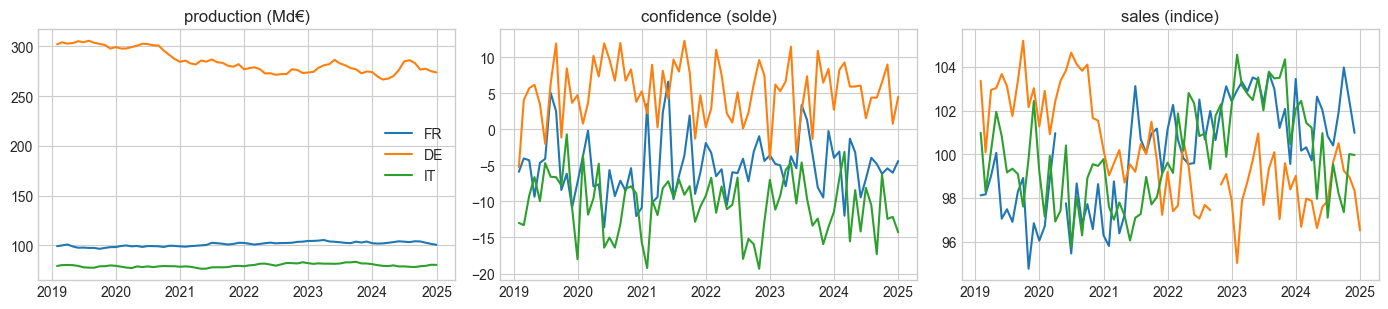

In [3]:
# Les trois pays : niveaux de production très différents, ventes de même niveau
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for country in countries:
    for ax, column in zip(axes, ['production', 'confidence']):
        ax.plot(X.loc[country, column], label=country)
    axes[2].plot(y.loc[country], label=country)
for ax, title in zip(axes, ['production (Md€)', 'confidence (solde)', 'sales (indice)']):
    ax.set_title(title)
axes[0].legend()
plt.tight_layout()

<a id="3"></a>
## 3 — Écrire un transformateur temporel : `PanelTimeSeriesTransformer`

Une sous-classe de `PanelTimeSeriesTransformer` n'écrit que `_fit` et `_transform`. Les méthodes
publiques `fit` et `transform` valident les données sur une copie, puis les lui passent, et
enregistrent les attributs de la convention sklearn (`is_panel_`, `n_features_in_`,
`feature_names_in_`). Le transformateur ci-dessous centre chaque colonne sur sa moyenne
d'entraînement.

In [4]:
# Transformateur temporel minimal
class Center(PanelTimeSeriesTransformer):
    # Apprentissage de la moyenne de chaque colonne
    def _fit(self, X, y=None):
        self.mean_ = X.mean()

    # Centrage
    def _transform(self, X):
        return X - self.mean_


center = Center().fit(X)
print('panel :', center.is_panel_, '| colonnes :', list(center.feature_names_in_))

# La moyenne apprise est commune aux trois pays
center.transform(X).groupby(level='country', sort=False).mean().round(1)

panel : True | colonnes : ['production', 'confidence']


,production,confidence
country,,
FR,-54.1,-1.7
DE,129.7,8.7
IT,-75.6,-7.0


La même classe accepte une série (`X.loc['FR']`) comme un panel. La moyenne apprise est celle du
panel entier : chaque pays reste décalé de sa moyenne propre (section 4).

### 3.1 — Ce que la validation refuse

La validation lève une `ValueError` pour une entrée qui n'est pas un `DataFrame`, des étiquettes
temporelles qui ne sont pas des dates, ou, au `transform`, des colonnes autres que celles du `fit`.
Des chaînes de dates et des `Period` sont acceptées : elles sont lues comme des dates (une période à
son premier instant).

In [5]:
# Fonction d'affichage de l'erreur levée par un appel
def show_error(label, call):
    try:
        call()
        print(f'{label:<28} accepté')
    except ValueError as error:
        print(f'{label:<28} ValueError : {error}')


show_error('série', lambda: center.transform(X['production']))
show_error('années entières', lambda: Center().fit(pd.DataFrame({'v': [1.0, 2.0]}, index=[2023, 2024])))
show_error('colonnes permutées', lambda: center.transform(X[['confidence', 'production']]))
show_error('périodes', lambda: Center().fit(pd.DataFrame({'v': [1.0, 2.0]}, index=pd.period_range('2024-01', periods=2, freq='M'))))

série                        ValueError : X must be a pandas DataFrame, got Series; pass series.to_frame() for a single series
années entières              ValueError : When time_col and panel_cols are None, the index must hold dates (datetimes, date strings or periods) for a time series, or be a MultiIndex for panel data.
colonnes permutées           ValueError : The feature names should match those that were passed during fit; same names in another order: ['confidence', 'production'] instead of ['production', 'confidence']
périodes                     accepté


Un couple (entité, date) répété, des dates non triées et des entités dont les lignes ne sont pas
contiguës lèvent aussi une `ValueError`, ou un simple avertissement sous `strict_validation=False`.
`auto_sort=True` trie une copie par entité puis par date ; le transformateur ne trie jamais sans
cette demande, ce qui protège les calculs qui dépendent de l'ordre des lignes.

In [6]:
# Lignes mélangées : refusées, signalées ou triées
shuffled = X.sample(frac=1, random_state=0)
show_error('lignes mélangées', lambda: Center().fit(shuffled))

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    Center(strict_validation=False).fit(shuffled)
print('strict_validation=False   ', '; '.join(sorted({str(w.message) for w in caught})))

print('auto_sort=True             ordre des pays :',
      Center(auto_sort=True).fit_transform(shuffled).index.get_level_values('country').unique().tolist())

lignes mélangées             ValueError : Panel entities are not contiguous in MultiIndex. Consider sorting by entity levels (e.g. X.sort_index()) or enabling auto_sort=True
strict_validation=False    Panel entities are not contiguous in MultiIndex. Consider sorting by entity levels (e.g. X.sort_index()) or enabling auto_sort=True; Time series not sorted within panel groups. Consider sorting by date within each entity (e.g. X.sort_index()) or enabling auto_sort=True
auto_sort=True             ordre des pays : ['DE', 'FR', 'IT']


### 3.2 — `DataFrame` plat et réversibilité

Sur un `DataFrame` plat, `time_col` et `panel_cols` nomment les colonnes de dates et d'entités. Par
défaut elles restent en place, et `_fit` les reçoit parmi les autres colonnes ;
`convert_cols_to_index=True` les passe dans l'index avant l'appel.

`ReversibleTransformerMixin` rend `inverse_transform` obligatoire et fournit
`_restore_structure_if_converted`, qui remet ces colonnes à leur place d'origine (et les `Period`
d'un index de périodes).

In [7]:
# Transformateur réversible sur un panel plat
class ReversibleCenter(Center, ReversibleTransformerMixin):
    def inverse_transform(self, X):
        return self._restore_structure_if_converted(X + self.mean_)


flat = X.reset_index()
flat_center = ReversibleCenter(time_col='date', panel_cols=['country'], convert_cols_to_index=True)
centered = flat_center.fit_transform(flat)
restored = flat_center.inverse_transform(centered)

print('entrée   :', flat.columns.tolist())
print('centrée  :', centered.index.names, centered.columns.tolist())
print('inversée :', restored.columns.tolist(), '| valeurs retrouvées :', np.allclose(restored[['production', 'confidence']], flat[['production', 'confidence']]))

entrée   : ['country', 'date', 'production', 'confidence']
centrée  : ['country', 'date'] ['production', 'confidence']
inversée : ['country', 'date', 'production', 'confidence'] | valeurs retrouvées : True


`InverseTransformer` enveloppe un transformateur **déjà ajusté** et échange `transform` et
`inverse_transform`. C'est une étape pré-ajustée : son `fit` ne fait rien et `clone` la rend telle
quelle, si bien qu'elle garde son ajustement dans `cross_validate` ou `GridSearchCV`.

In [8]:
# Étape qui ramène des données centrées à leur échelle d'origine
undo = InverseTransformer(flat_center)
print(undo.fit(centered).transform(centered).equals(restored))

True


<a id="4"></a>
## 4 — Ajuster un transformateur par entité : `PanelwiseTransformer`

`PanelwiseTransformer` clone un transformateur sklearn (ou un pipeline) pour chaque entité et ajuste
chaque clone sur les seules lignes de son entité.

![Un transformateur ajusté par entité](../docs/assets/panelwise_principle.png)

Un `StandardScaler` appliqué au panel entier laisse chaque pays à son niveau ; ajusté par pays, il
met les trois pays à la même échelle, celle de leurs écarts propres, qui expliquent les ventes.

{('FR',): [101.3, -5.1], ('DE',): [285.1, 5.3], ('IT',): [79.8, -10.5]}


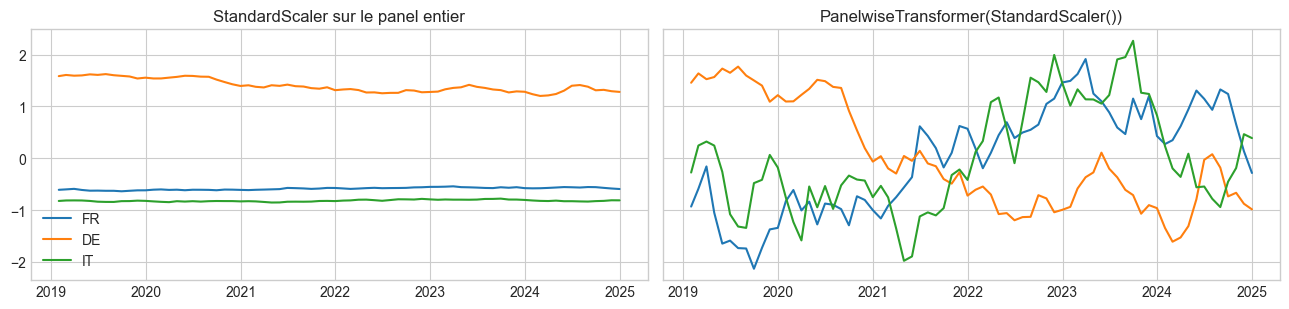

In [9]:
# Mise à l'échelle globale et par pays
global_scaled = StandardScaler().set_output(transform='pandas').fit_transform(X)
scaler = PanelwiseTransformer(StandardScaler())
X_scaled = scaler.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
for country in countries:
    axes[0].plot(global_scaled.loc[country, 'production'], label=country)
    axes[1].plot(X_scaled.loc[country, 'production'], label=country)
axes[0].set_title('StandardScaler sur le panel entier')
axes[1].set_title('PanelwiseTransformer(StandardScaler())')
axes[0].legend()
plt.tight_layout()

# Un clone ajusté par pays, rangé par clé d'entité
print({key: transformer.mean_.round(1).tolist() for key, transformer in scaler.transformers_.items()})

Les clés de `transformers_` sont des tuples ; `get_entity_transformer('DE')` accepte la valeur
seule. La sortie garde l'index, les colonnes et l'ordre des lignes de l'entrée.

### 4.1 — Opérations sur les lignes voisines

Une variation, un décalage ou une moyenne mobile lisent les lignes voisines. Appliqués au panel
entier, ils font lire à la première ligne d'un pays la dernière ligne du pays précédent :

In [10]:
# Variation mensuelle de la production, sur le panel entier ou par pays
growth = FunctionTransformer(lambda df: df.pct_change(), feature_names_out='one-to-one')
pd.DataFrame({
    'panel entier': X[['production']].pct_change()['production'],
    'par pays': PanelwiseTransformer(growth).fit_transform(X[['production']])['production'],
}).loc[[('DE', '2019-01-31'), ('DE', '2019-02-28'), ('IT', '2019-01-31')]].round(3)

panel entier  par pays
country date                              
DE      2019-01-31         1.999       NaN
        2019-02-28         0.007     0.007
IT      2019-01-31        -0.710       NaN

### 4.2 — Paramétrer chaque entité

Trois modes fixent le transformateur de chaque entité :

| Mode | `transformer` | Effet |
|---|---|---|
| Simple | un estimateur | cloné à l'identique |
| Fabrique | `Callable[[clé], estimateur]` | appelé avec la clé de chaque entité |
| `entity_kwargs` | un estimateur et `{entité: paramètres}` | cloné, puis `set_params` par entité ; `default_entity_kwargs` pour les autres |

Une fabrique l'emporte sur `entity_kwargs`, ignoré avec un avertissement. Un transformateur qui
change le nombre de colonnes donne ses noms par `get_feature_names_out`.

In [11]:
# Fabrique et entity_kwargs : l'Italie centrée sans réduction
factory = PanelwiseTransformer(lambda key: StandardScaler(with_std=key != ('IT',)))
per_entity = PanelwiseTransformer(StandardScaler(), entity_kwargs={'IT': {'with_std': False}})
print('mêmes sorties :', factory.fit_transform(X).equals(per_entity.fit_transform(X)))

# Une composante principale par pays
PanelwiseTransformer(PCA(n_components=1)).fit_transform(X).groupby(level='country', sort=False).std().round(2)

mêmes sorties : True


,pca0
country,
FR,4.13
DE,11.60
IT,4.10


### 4.3 — Panel en colonnes, entités inconnues, échecs

Sur un `DataFrame` plat, `panel_cols` nomme les colonnes d'entités et `time_col` (défaut `'date'`)
celle des dates : elles sont rendues inchangées. Une entité absente du `fit`, ou dont le clone
échoue, suit `error_handling` : `'raise'` (défaut) lève l'erreur, `'warn'` et `'ignore'` rendent ses
lignes inchangées. Les entités en échec au `fit` sont listées dans `failed_entities_`.

In [12]:
# Panel plat : colonnes d'identifiants conservées
print(PanelwiseTransformer(StandardScaler(), panel_cols=['country']).fit_transform(flat).columns.tolist())

# Un pays absent du fit
spain = X.loc[['FR']].rename(index={'FR': 'ES'})
show_error("error_handling='raise'", lambda: scaler.transform(spain))
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    unchanged = PanelwiseTransformer(StandardScaler(), error_handling='warn').fit(X).transform(spain)
print("error_handling='warn'      ", caught[0].message, '| lignes inchangées :', unchanged.equals(spain))


# Un transformateur qui échoue sur un pays
class FailsOnGermany(StandardScaler):
    def fit(self, X, y=None):
        if X['production'].mean() > 200:
            raise RuntimeError('échec simulé')
        return super().fit(X, y)


with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    partial = PanelwiseTransformer(FailsOnGermany(), error_handling='warn').fit(X)
print('failed_entities_ :', partial.failed_entities_, '| clones ajustés :', list(partial.transformers_))

['country', 'date', 'production', 'confidence']
error_handling='raise'       ValueError : Entity ('ES',) was not seen during fit
error_handling='warn'       Entity ('ES',) was not seen during fit. Using untransformed data. | lignes inchangées : True
failed_entities_ : [('DE',)] | clones ajustés : [('FR',), ('IT',)]


`n_jobs` parallélise l'ajustement des clones (joblib) ; la transformation reste séquentielle.
`inverse_transform` inverse chaque entité par son propre clone, si le transformateur de base est
réversible :

In [13]:
print('n_jobs=2, même sortie :', PanelwiseTransformer(StandardScaler(), n_jobs=2).fit_transform(X).equals(X_scaled))
print('inversion exacte      :', np.allclose(scaler.inverse_transform(X_scaled), X))

n_jobs=2, même sortie : True
inversion exacte      : True


<a id="5"></a>
## 5 — Transformer la cible : `XYPipeline`

Pour prévoir les ventes du mois suivant, chaque ligne de `X` doit être associée à la cible **un mois
plus tard**, pays par pays. C'est une transformation de `y`, que `Pipeline` ne sait pas faire : une
étape qui rendrait la paire `(X, y)` la passerait tout entière, comme `X`, à l'étape suivante.

Une **étape XY** hérite de `XYTransformerMixin`, écrit `_fit` et `_transform`, et rend la paire
`(X, y)` quand elle reçoit une cible, `X` seul sinon.

In [14]:
# Étape XY : cible à l'horizon de prévision, pays par pays
class TargetLead(BaseEstimator, XYTransformerMixin):
    def __init__(self, horizon=1):
        self.horizon = horizon

    def _fit(self, X, y):
        return self

    def _transform(self, X, y=None):
        if y is None:
            return X
        return X, y.groupby(level='country').shift(-self.horizon)


# Dans un Pipeline sklearn, la paire devient le X de l'étape suivante
try:
    Pipeline([('lead', TargetLead()), ('model', Ridge())]).fit(X, y)
except Exception as error:
    print('Pipeline   :', type(error).__name__, ':', str(error)[:90])

Pipeline   : ValueError : setting an array element with a sequence. The requested array has an inhomogeneous shape a


`XYPipeline` donne la cible aux étapes XY et lit leur sortie comme la paire `(X, y)`. Il traite les
autres étapes exactement comme `Pipeline` : `fit_transform(X, y)` à l'entraînement, `transform(X)`
sans la cible. Une étape est XY **par déclaration** (héritage de `XYTransformerMixin` ou de
`XYPanelTimeSeriesTransformer`), ce que teste `is_xy_transformer`.

![Le parcours de X et y dans un XYPipeline](../docs/assets/xy_pipeline_flow.png)

In [15]:
# Pipeline de prévision à un mois
pipe = XYPipeline([
    ('lead', TargetLead(horizon=1)),                    # étape XY
    ('scale', PanelwiseTransformer(StandardScaler())),  # étape ordinaire : X seul
    ('drop', DropNaNTarget()),                          # étape XY : lignes sans cible
    ('model', Ridge()),
])
print('étapes XY :', {name: is_xy_transformer(step) for name, step in pipe.steps})

# Passe d'entraînement des étapes intermédiaires
X_train, y_train = pipe[:-1].fit_transform(X, y)
print('entraînement :', X_train.shape, '| cibles manquantes :', int(y_train.isna().sum()))

# Passe de prédiction : une prévision par ligne de X
pipe.fit(X, y)
print('prédiction   :', pipe.predict(X).shape)

étapes XY : {'lead': True, 'scale': False, 'drop': True, 'model': False}
entraînement : (209, 2) | cibles manquantes : 0
prédiction   : (216,)


À l'entraînement, chaque pays perd sa dernière ligne (cible future inconnue) et la ligne qui précède
chaque vente manquante : 216 − 3 − 4 = 209 lignes. À la prédiction, aucune étape ne reçoit la
cible : la prévision de la ligne du 31 décembre 2024 vise janvier 2025. Les méthodes de prédiction
refusent un argument `y` :

In [16]:
try:
    pipe.predict(X, y=y)
except TypeError as error:
    print('TypeError :', error)

TypeError : XYPipeline.predict does not take y: a prediction never depends on the target; use score(X, y) to evaluate the pipeline


<a id="6"></a>
## 6 — Retirer les lignes sans cible : `DropNaNTarget`

`DropNaNTarget`, placée juste avant l'estimateur, retire les lignes sans cible quand elle reçoit
`y` (`fit`, `score`) et n'en retire aucune sans `y` (`predict`). `score(X, y)` fait passer la cible
de test par `TargetLead` puis `DropNaNTarget`, sans rien réajuster.

In [17]:
print('score (R²) sur le jeu d\'entraînement :', round(pipe.score(X, y), 3))

# Un paramètre par ligne suit les lignes gardées : les 216 poids deviennent 209
weights = np.where(X.index.get_level_values('date').year >= 2023, 2.0, 1.0)
print('coefficients pondérés :', pipe.fit(X, y, model__sample_weight=weights).named_steps['model'].coef_.round(2))

score (R²) sur le jeu d'entraînement : 0.952
coefficients pondérés : [2.04 0.98]


Les lignes gardées sont localisées sur l'index de `y` (sinon de `X`) : un index pandas sans doublon
est nécessaire. Sur des tableaux numpy dont une étape XY change le nombre de lignes, un paramètre
par ligne est refusé par une `ValueError`.

En validation croisée, le score par défaut (`scoring=None`) est `pipe.score`. Un scorer textuel
compare au contraire `pipe.predict(X_test)` au `y_test` **brut** : sans le décalage d'un mois, et
avec ses NaN. Le score d'un pli qui contient une cible manquante vaut alors NaN :

In [18]:
cv = PanelOutOfSampleSplit(n_splits=4, test_size=6, gap=1)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    textual = cross_validate(pipe, X, y, cv=cv, scoring='r2')['test_score']
pd.DataFrame({
    "scoring=None (pipe.score)": cross_validate(pipe, X, y, cv=cv)['test_score'],
    "scoring='r2' (y_test brut)": textual,
}, index=pd.Index(range(1, 5), name='pli')).round(3)

,scoring=None (pipe.score),scoring='r2' (y_test brut)
pli,,
1,0.762,0.558
2,0.892,0.188
3,0.911,0.306
4,0.899,NaN


Hors du pli qui contient décembre 2024, le scorer textuel donne un nombre, mais faux : il compare la
prévision du mois suivant aux ventes du mois courant. Toute transformation de la cible par une étape
XY demande donc le score par défaut, ou un scorer qui reproduise cette transformation.

<a id="7"></a>
## 7 — Agréger sur une période glissante : `RollingAggregator`

`RollingAggregator` remplace chaque colonne par son agrégat sur une **période calendaire
glissante**, pays par pays. Sur une grille mensuelle, `window='Q'` fait de chaque mois un
**trimestre glissant**. Le sens de la fenêtre suit la position des dates dans leur période
(`alignment='auto'`) :

![Sens de la fenêtre](../docs/assets/rolling_window_alignment.png)

In [19]:
# Même série sur une grille de fin de mois (ME) et de début de mois (MS)
months_end = pd.date_range('2024-01-31', periods=6, freq='ME')
months_start = pd.date_range('2024-01-01', periods=6, freq='MS')
x = pd.DataFrame({'x': [1.0, 2.0, 3.0, 4.0, 5.0, 6.0]}, index=months_end)

past = RollingAggregator(window='Q').fit(x)
future = RollingAggregator(window='Q').fit(x.set_axis(months_start))
pd.DataFrame({
    'x': x['x'].to_numpy(),
    f"ME → {past.alignments_[()]}": past.transform(x)['x'].to_numpy(),
    f"MS → {future.alignments_[()]}": future.transform(x.set_axis(months_start))['x'].to_numpy(),
}, index=months_end.strftime('%b'))

,x,ME → past,MS → future
Jan,1.0,NaN,6.0
Feb,2.0,NaN,9.0
Mar,3.0,6.0,12.0
Apr,4.0,9.0,15.0
May,5.0,12.0,NaN
Jun,6.0,15.0,NaN


Une fenêtre à laquelle il manque une valeur (bord des données, NaN, date absente de la grille)
donne NaN. Une grille sans position (jours, semaines) demande `alignment='past'` ou `'future'`, et
la grille doit s'emboîter exactement dans la fenêtre (`Q` sur `M`, `Y` sur `Q`, `W` sur `D`...) :

In [20]:
days = pd.DataFrame({'x': np.ones(10)}, index=pd.date_range('2024-01-01', periods=10, freq='D'))
show_error('grille journalière, auto', lambda: RollingAggregator(window='W').fit(days))
print('alignment=\'past\'          ', RollingAggregator(window='W', alignment='past').fit_transform(days)['x'].tolist())

grille journalière, auto     ValueError : alignment='auto' needs a period-start or period-end grid, the grid of the time series ('D') has no position: pass alignment='past' or 'future'
alignment='past'           [nan, nan, nan, nan, nan, nan, 7.0, 7.0, 7.0, 7.0]


### 7.1 — Deux passes

`RollingAggregator` est une étape XY à deux passes :

- `fit_transform(X, y)` (entraînement) agrège `X` et `y` (`target_agg`) ;
- `transform(X, y)` (prédiction, `score`) agrège `X` seul et rend `y` **inchangé**.

La convention sert le cas où la cible d'évaluation est **publiée par trimestre** : l'indice
trimestriel des ventes est la moyenne des trois mois. Le modèle apprend sur des trimestres
glissants, trois fois plus nombreux que les trimestres publiés, et `score` compare ses prédictions
aux indices trimestriels tels qu'ils sont publiés.

In [21]:
# Indices trimestriels publiés : moyenne des trois mois, sur la ligne de fin de trimestre
roll = RollingAggregator(window='Q', agg='mean', target_agg='mean')
_, y_rolling = roll.fit_transform(X, y)
quarter_end = X.index.get_level_values('date').month % 3 == 0
y_published = y_rolling.where(quarter_end)
print('trimestres glissants :', int(y_rolling.notna().sum()), '| trimestres publiés :', int(y_published.notna().sum()))
print('passe de prédiction, y inchangé :', roll.transform(X, y_published)[1].equals(y_published))

# Apprentissage sur les trimestres glissants jusqu'à 2023, évaluation sur les trimestres publiés de 2024
test_2024 = X.index.get_level_values('date').year == 2024
quarterly = XYPipeline([
    ('scale', PanelwiseTransformer(StandardScaler())),
    ('roll', RollingAggregator(window='Q', agg='mean', target_agg='mean')),
    ('drop', DropNaNTarget()),
    ('fill', SimpleImputer()),      # fenêtres incomplètes de X à la prédiction
    ('model', Ridge()),
]).fit(X[~test_2024], y[~test_2024])
print('R² sur les trimestres publiés de 2024 :', round(quarterly.score(X[test_2024], y_published[test_2024]), 3))

trimestres glissants : 202 | trimestres publiés : 68
passe de prédiction, y inchangé : True
R² sur les trimestres publiés de 2024 : 0.805


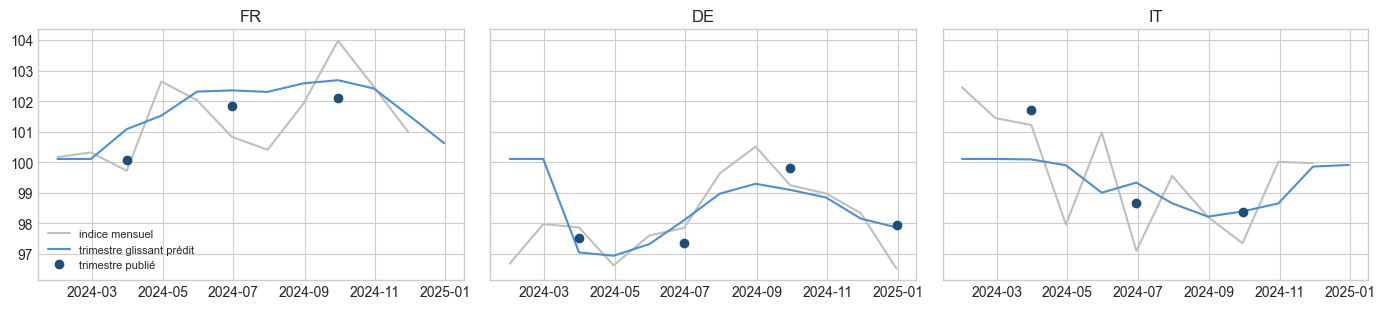

In [22]:
# Prédictions de 2024 (une par mois, trimestre glissant) et trimestres publiés
predicted = pd.Series(quarterly.predict(X[test_2024]), index=X.index[test_2024])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, country in zip(axes, countries):
    ax.plot(y.loc[country].loc['2024':], color='#bfbfbf', label='indice mensuel')
    ax.plot(predicted.loc[country], color='#4a90d9', label='trimestre glissant prédit')
    ax.plot(y_published.loc[country].loc['2024':].dropna(), 'o', color='#1f4e79', label='trimestre publié')
    ax.set_title(country)
axes[0].legend(fontsize=8)
plt.tight_layout()

Les premières lignes du jeu de test (janvier et février 2024) ont une fenêtre incomplète : leurs
covariables agrégées sont NaN, et `SimpleImputer` les comble. Sans lui, `predict` échouerait ; un
estimateur qui tolère les NaN est une autre solution.

Seule une agrégation qui reconstruit la quantité publiée suit cette convention. Un logarithme ou un
taux de croissance de la cible doivent s'appliquer aussi à la cible de test, par un
`TransformedTargetRegressor` autour de l'estimateur.

`agg` accepte un dictionnaire par colonne, avec une clé `'__default__'` ; `suffix` garde les
colonnes d'origine et ajoute les agrégats :

In [23]:
RollingAggregator(window='Q', agg={'production': 'sum', '__default__': 'mean'}, suffix='_q').fit_transform(X).loc['FR'].head(4).round(1)

,production,confidence,production_q,confidence_q
date,,,,
2019-01-31,99.3,-5.9,NaN,NaN
2019-02-28,100.0,-4.0,NaN,NaN
2019-03-31,101.0,-4.3,300.2,-4.7
2019-04-30,99.0,-9.3,300.0,-5.9


<a id="8"></a>
## 8 — Valider le pipeline

`XYPipeline` est un estimateur sklearn : `GridSearchCV` règle ses paramètres
(`étape__paramètre`) sur les plis d'un splitter de `tsforecast.crossvals`. Les ventes d'un mois
étant publiées le mois suivant, un horizon `h = 1` et un délai `d = 1` donnent `gap = h + d − 1 = 1`.

In [24]:
# Réglage de la régularisation sur quatre plis de six mois
search = GridSearchCV(pipe, {'model__alpha': [0.1, 1.0, 10.0, 100.0]}, cv=cv).fit(X, y)
print('meilleur alpha :', search.best_params_['model__alpha'])
pd.DataFrame(search.cv_results_)[['param_model__alpha', 'mean_test_score', 'std_test_score']].round(3)

meilleur alpha : 10.0


,param_model__alpha,mean_test_score,std_test_score
0,0.1,0.862,0.064
1,1.0,0.866,0.060
2,10.0,0.895,0.031
3,100.0,0.813,0.025


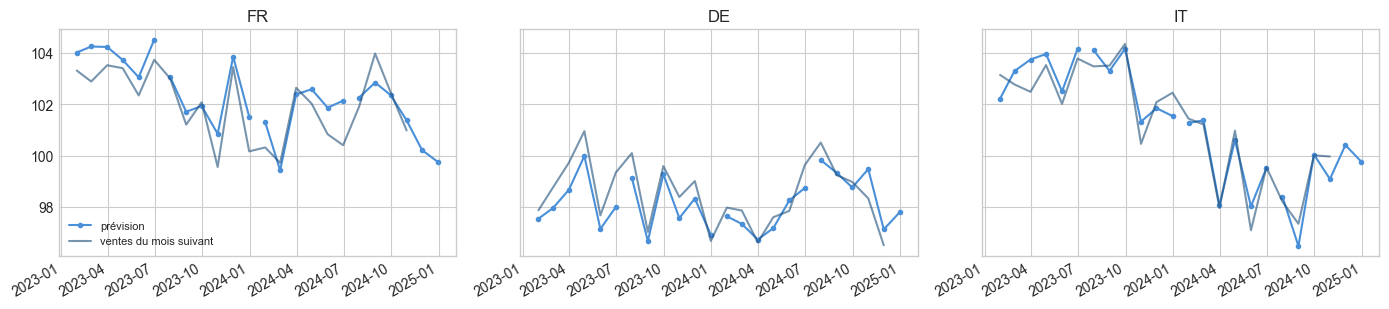

In [25]:
# Prévisions hors échantillon de chaque pli, comparées aux ventes du mois suivant
best = search.best_estimator_
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
target = y.groupby(level='country').shift(-1)
for fold, (train, test) in enumerate(cv.split(X)):
    fitted = best.fit(X.iloc[train], y.iloc[train])
    forecast = pd.Series(fitted.predict(X.iloc[test]), index=X.index[test])
    for ax, country in zip(axes, countries):
        ax.plot(forecast.loc[country], color='#4a90d9', marker='o', markersize=3, label='prévision' if fold == 0 else None)
for ax, country in zip(axes, countries):
    ax.plot(target.loc[country].loc['2023-01':], color='#1f4e79', alpha=0.6, label='ventes du mois suivant')
    ax.set_title(country)
axes[0].legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()

<a id="9"></a>
## 9 — Points d'attention

| Situation | Comportement |
|---|---|
| Série passée à un transformateur temporel | Refusée : `series.to_frame()` |
| Années entières, `RangeIndex` comme dates | Refusés : convertir avec `pd.to_datetime` ; chaînes de dates et `Period` acceptées |
| Lignes non triées, entités non contiguës, doublons | `ValueError` ; avertissement sous `strict_validation=False` ; `auto_sort=True` trie une copie |
| `time_col` / `panel_cols` laissées en colonnes | Reçues par `_fit` et `_transform`, comptées dans `n_features_in_` ; `convert_cols_to_index=True` les passe dans l'index |
| Variation, décalage ou moyenne mobile sur un panel | À appliquer par entité (`PanelwiseTransformer`) : sinon une entité lit la précédente |
| Mise à l'échelle par entité | Efface les écarts de niveau entre entités : à réserver aux relations qui portent sur les écarts propres |
| Entité absente du `fit` | `error_handling` : `ValueError`, ou lignes rendues inchangées |
| Étape qui doit transformer `y` | Hériter de `XYTransformerMixin` : la signature ne suffit pas |
| `predict(X, y=...)` | `TypeError` : une prédiction ne dépend pas de la cible ; évaluer par `score(X, y)` |
| Scorer textuel en validation croisée | Compare au `y_test` brut (NaN, cible non transformée) : préférer `scoring=None` ou un scorer adapté |
| `sample_weight` derrière `DropNaNTarget` | Suit les lignes gardées, localisées sur un index pandas unique |
| Fenêtre incomplète de `RollingAggregator` | NaN : retirées par `DropNaNTarget` à l'entraînement, à imputer à la prédiction |
| Logarithme ou croissance de la cible | `TransformedTargetRegressor`, jamais une étape qui ne transformerait que la cible d'entraînement |

<a id="10"></a>
## 10 — Récapitulatif

| Besoin | Outil |
|---|---|
| Transformateur qui valide séries et panels | sous-classe de `PanelTimeSeriesTransformer` (`_fit`, `_transform`) |
| Transformation réversible | `ReversibleTransformerMixin` (`inverse_transform`, `_restore_structure_if_converted`) |
| Inverser un transformateur ajusté dans un pipeline | `InverseTransformer` |
| Un transformateur sklearn par entité | `PanelwiseTransformer` (simple, fabrique, `entity_kwargs`) |
| Transformer `X` et `y` dans un pipeline | `XYPipeline` et une étape `XYTransformerMixin` |
| Étape XY avec validation séries et panels | `XYPanelTimeSeriesTransformer` |
| Retirer les lignes sans cible | `DropNaNTarget`, juste avant l'estimateur |
| Agréger sur une période glissante | `RollingAggregator` |
| Reconnaître une étape XY | `is_xy_transformer` |

Pour aller plus loin : la documentation du package (concept et tutoriel *Extensions de
scikit-learn*), le notebook `2 - QB - Mixed frequencies.ipynb`, qui place `HighFrequencyImputer` et
`RollingAggregator` dans un même `XYPipeline`, et la référence API de chaque classe.